# Лабораторная работа 4. Подготовка признаков

**Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ**
Дисциплина «Разведочный анализ и алгоритмы классификации»

**Этап CRISP-DM:** Data preparation. Датасет — Online Shoppers Purchasing Intention (тот же, что в lab2–lab3, lab5 и дашборде).

**Цель:** по результатам разведочного анализа выбрать и обосновать преобразование каждого признака и собрать воспроизводимый конвейер подготовки данных (`src/features.py`), которым пользуются модели (lab5), дашборд (lab6) и итоговый проект.

**Задачи:**
1. Определить тип шкалы каждого признака и способ кодирования.
2. Показать, почему целочисленные коды нельзя кодировать порядковыми номерами.
3. Обработать редкие категории, скошенность, выбросы, дубликаты.
4. Оценить мультиколлинеарность.
5. Разбить данные на обучающую и тестовую выборки без утечки информации.
6. Проверить, что выбранные преобразования действительно улучшают модели, чувствительные к масштабу.

## Сводка решений

| Признак | Тип (по lab2) | Преобразование для kNN / логистической регрессии / SVM | Для деревьев и ансамблей | Почему |
|---|---|---|---|---|
| `Administrative`, `Informational`, `ProductRelated` | счётчик, сильно скошен, много нулей | `log1p` → `StandardScaler` | без изменений | выравнивание масштаба и хвостов; деревьям масштаб безразличен |
| `*_Duration` (3 признака) | секунды, сильно скошены; ноль — особенность GA, не пропуск | `log1p` → `StandardScaler` | без изменений | то же |
| `PageValues` | ≥ 0, 77,9 % нулей, длинный хвост | `log1p` → `StandardScaler` | без изменений | то же |
| `BounceRates`, `ExitRates` | доли в [0; 0,2], пик на 0,2 | `StandardScaler` | без изменений | значения < 0,2, `log1p` их почти не меняет |
| `SpecialDay` | 6 уровней 0…1, порядок очевиден (ближе/дальше к празднику) | `StandardScaler` | без изменений | единственный признак с очевидным порядком; он уже записан на числовой шкале с равным шагом, поэтому кодировать его заново не нужно |
| `Month` | номинальный, 10 месяцев (нет января и апреля) | one-hot | one-hot | порядок календаря есть, но он циклический и неполный, а доля покупок по месяцам немонотонна (п. 1) |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | номинальные **коды** | one-hot, категории < 1 % → `other` | то же | номер кода — идентификатор, а не величина (п. 1) |
| `VisitorType` | номинальный, 3 значения | one-hot (`Other` < 1 % → `other`) | то же | — |
| `Weekend` | бинарный | 0/1 | 0/1 | — |
| `Revenue` | целевая, бинарная | 0/1 | 0/1 | — |
| 125 полных дубликатов | одностраничные сессии без покупки | оставить | оставить | п. 4 |

Пропусков нет, импутация не требуется. Всё это реализовано в `src/features.py` (функции `make_preprocessor` и `encode_for_trees`), а ниже — проверки и обоснования.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from src.data import load, NUMERIC, NOMINAL, BINARY, TARGET, MONTH_ORDER, MONTH_RU
from src.features import (make_preprocessor, split, pretty_names, SKEWED, NOT_SKEWED,
                          RARE_MIN_FREQUENCY, RANDOM_STATE, TEST_SIZE)
from src import viz
from sklearn import set_config
set_config(display="text")
viz.setup()
pd.set_option("display.width", 160)
df = load()
print(df.shape)

(12330, 18)


## 1. Почему коды нельзя кодировать порядковыми номерами
Label encoding (замена категории на число) допустим только для порядковых признаков с очевидным порядком. Проверю, есть ли порядок у целочисленных кодов: если бы код был порядковой величиной, доля покупок по кодам хотя бы примерно менялась бы монотонно. Линия соединяет коды в порядке возрастания номера — именно этот порядок навязала бы модели кодировка «как есть».

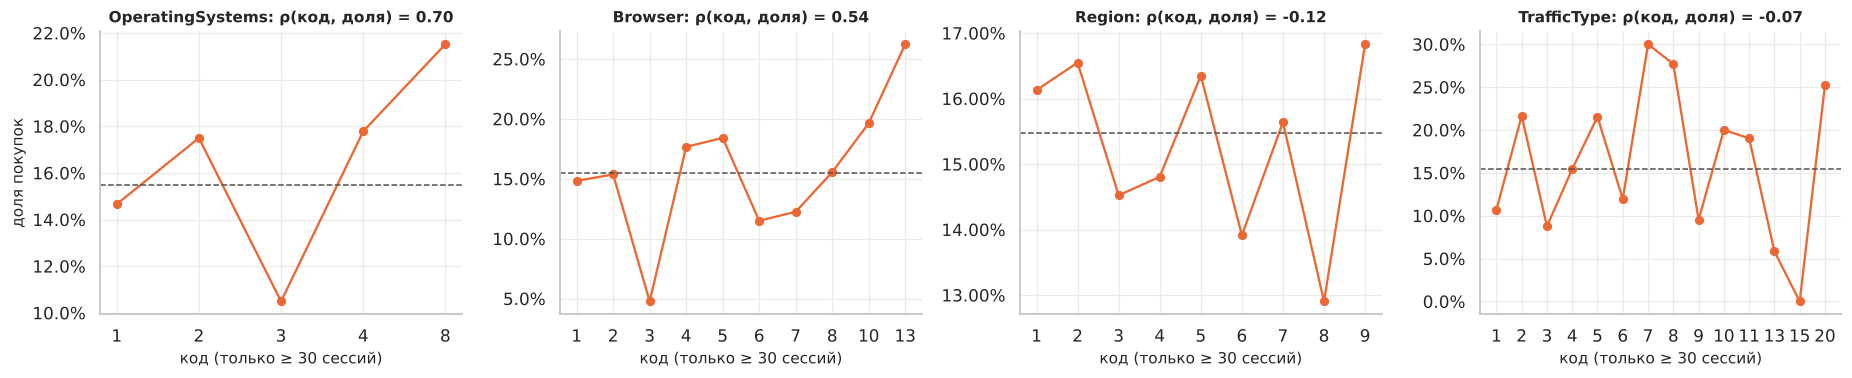

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for a, c in zip(axes, ["OperatingSystems", "Browser", "Region", "TrafficType"]):
    g = df.groupby(c, observed=True)[TARGET].agg(["mean", "size"])
    g = g[g["size"] >= 30]  # только коды с достаточным числом сессий
    codes = g.index.astype(int)
    xpos = np.arange(len(codes))
    a.plot(xpos, g["mean"], "-o", color=viz.ORANGE, ms=5, lw=1.5)
    a.axhline(df[TARGET].mean(), ls="--", color="#52514e", lw=1)
    rho = stats.spearmanr(codes, g["mean"]).statistic
    a.set_title(f"{c}: ρ(код, доля) = {rho:.2f}", fontsize=10)
    a.set_xlabel("код (только ≥ 30 сессий)"); a.set_xticks(xpos, codes)
    a.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("доля покупок")
plt.tight_layout(); plt.show()

**Что показывают графики.** Если бы номер кода был величиной, доля покупок менялась бы с ним хоть сколько-нибудь последовательно. На деле:
* у `Region` и `TrafficType` линия скачет вверх-вниз (ρ = −0,12 и −0,07);
* у `OperatingSystems` и `Browser` ранговая корреляция получилась положительной (0,70 и 0,54), но это всего 5 и 10 точек, и внутри — резкие провалы: ОС 3 (10,5 %) стоит между ОС 2 (17,5 %) и ОС 4 (17,8 %), браузер 3 (4,8 %) — между браузерами 2 и 4 (15,4 % и 17,7 %).

Главный аргумент даже не график, а смысл: коды присвоены авторами датасета при анонимизации, браузер «13» не «в 13 раз больше» браузера «1», а расстояние между ОС 2 и 3 ничем не отличается от расстояния между ОС 2 и 8. При label encoding модель получила бы эти несуществующие порядок и расстояния (особенно kNN и логистическая регрессия, у которой на код был бы один общий коэффициент). Поэтому — **one-hot**.

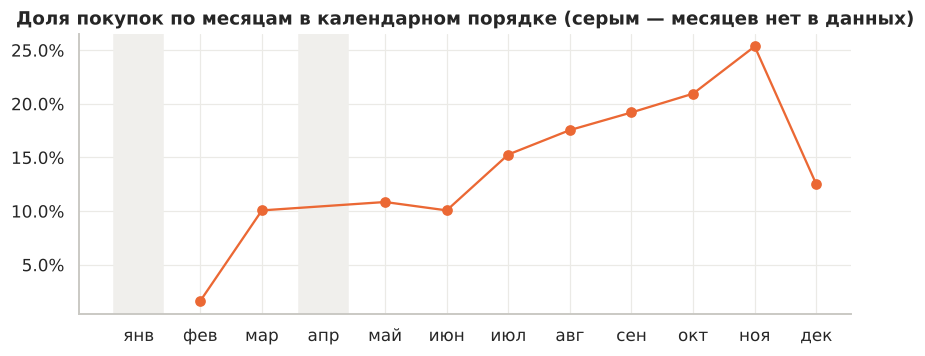

In [3]:
g = df.groupby("Month", observed=True)[TARGET].mean().reindex(MONTH_ORDER)
calendar_no = {"Feb": 2, "Mar": 3, "May": 5, "June": 6, "Jul": 7, "Aug": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12}
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot([calendar_no[m] for m in MONTH_ORDER], g.values, "-o", color=viz.ORANGE)
ax.set_xticks(range(1, 13), ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"])
for m in [1, 4]:
    ax.axvspan(m - .4, m + .4, color="#f0efec")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Доля покупок по месяцам в календарном порядке (серым — месяцев нет в данных)")
plt.tight_layout(); plt.show()

У `Month` порядок формально есть (календарь), но:
* он **циклический** — декабрь соседствует с январём, а порядковый номер делает их самыми далёкими;
* в данных нет января и апреля, так что шаг между соседними номерами неравномерный;
* доля покупок по месяцам немонотонна: падает с 10,9 % в мае до 10,1 % в июне, растёт до 25,4 % в ноябре и снова падает до 12,5 % в декабре.

Порядковый номер месяца навязал бы линейной модели одну «скорость роста» на весь год. Поэтому `Month` тоже кодирую one-hot: у каждого месяца свой столбец и свой коэффициент.

## 2. Редкие категории
`OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist")` объединяет категории, которые встречаются реже чем в 1 % обучающих сессий, в один столбец `<признак>_other`. Туда же попадёт и категория, которой не было в обучающей выборке, — модель не упадёт на новом коде.

In [4]:
X_train, X_test, y_train, y_test = split(df)
pre_tree = make_preprocessor("tree").fit(X_train)
ohe = pre_tree.named_transformers_["cat"]
rows = []
for feat, cats, infreq in zip(NOMINAL, ohe.categories_, ohe.infrequent_categories_):
    infreq = [] if infreq is None else list(infreq)
    n_inf = int(X_train[feat].isin(infreq).sum())
    rows.append({"признак": feat, "категорий в train": len(cats), "столбцов после one-hot": len(cats) - len(infreq) + (1 if infreq else 0),
                 "объединены в other": ", ".join(map(str, infreq)) if infreq else "—",
                 "сессий в other (train)": n_inf})
rare = pd.DataFrame(rows).set_index("признак")
rare

,категорий в train,столбцов после one-hot,объединены в other,сессий в other (train)
признак,,,,
Month,10,10,—,0
OperatingSystems,8,5,"5, 6, 7, 8",93
Browser,13,8,"3, 7, 9, 11, 12, 13",184
Region,9,9,—,0
TrafficType,20,12,"7, 9, 12, 14, 15, 16, 17, 18, 19",140
VisitorType,3,3,Other,74


**Результат на обучающей выборке:**
* `OperatingSystems`: 8 кодов → 5 столбцов (коды 5, 6, 7, 8 → `other`, 93 сессии);
* `Browser`: 13 → 8 (коды 3, 7, 9, 11, 12, 13 → `other`, 184 сессии);
* `TrafficType`: 20 → 12 (9 редких кодов → `other`, 140 сессий);
* `VisitorType`: `Other` (74 сессии в train) отдельным столбцом остаётся, но под именем `VisitorType_other`;
* `Month` и `Region` — без изменений.

Итого после one-hot 47 бинарных столбцов вместо 6 номинальных признаков (а без объединения было бы 63). Порог 1 % выбран так, чтобы в каждом столбце было хотя бы ~100 сессий: оценка по одной-двум сессиям (как у браузера 9 или трафика 12 и 17) — шум, на котором модель будет переобучаться.

## 3. Скошенность числовых признаков: `log1p` и стандартизация
Для моделей, основанных на расстояниях и линейных комбинациях (kNN, логистическая регрессия, SVM), масштаб признаков напрямую влияет на результат: `ProductRelated_Duration` в секундах (до 64 000) «перекричит» `ExitRates` (до 0,2). Поэтому для них: `log1p` для скошенных признаков → `StandardScaler`. Деревья и их ансамбли разбивают признак порогами и не чувствительны к монотонным преобразованиям, поэтому для них числовые признаки остаются в исходных единицах — это ещё и удобнее при интерпретации (lab5, дашборд).

In [5]:
pre_lin = make_preprocessor("linear").fit(X_train)
Z_train = pre_lin.transform(X_train)
sk = pd.DataFrame({
    "асимметрия до": X_train[NUMERIC].skew(),
    "асимметрия после log1p": pd.concat([np.log1p(X_train[SKEWED]), X_train[NOT_SKEWED]], axis=1)[NUMERIC].skew(),
    "среднее после (train)": Z_train[NUMERIC].mean(),
    "ст. откл. после (train)": Z_train[NUMERIC].std(),
})
sk.round(3)

,асимметрия до,асимметрия после log1p,среднее после (train),ст. откл. после (train)
Administrative,1.967,0.564,0.0,1.0
Administrative_Duration,5.679,0.254,-0.0,1.0
Informational,4.142,2.028,-0.0,1.0
Informational_Duration,7.702,1.915,-0.0,1.0
ProductRelated,4.372,-0.059,0.0,1.0
ProductRelated_Duration,8.009,-1.421,-0.0,1.0
BounceRates,2.924,2.924,0.0,1.0
ExitRates,2.130,2.130,0.0,1.0
PageValues,6.187,1.800,0.0,1.0
SpecialDay,3.261,3.261,-0.0,1.0


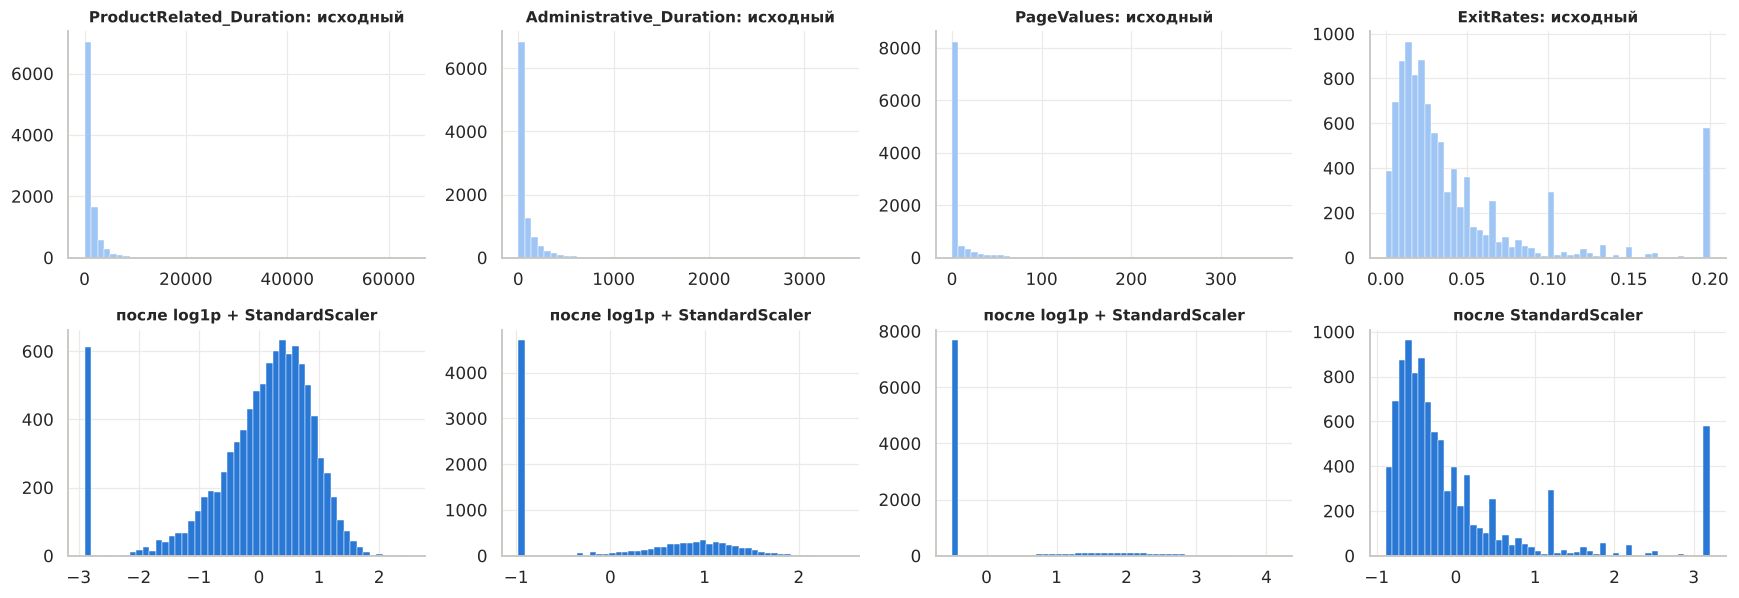

In [6]:
show = ["ProductRelated_Duration", "Administrative_Duration", "PageValues", "ExitRates"]
fig, axes = plt.subplots(2, 4, figsize=(16, 5.6))
for j, c in enumerate(show):
    axes[0, j].hist(X_train[c], bins=50, color="#9ec5f4", edgecolor="white", linewidth=0.3)
    axes[0, j].set_title(f"{c}: исходный", fontsize=10)
    axes[1, j].hist(Z_train[c], bins=50, color=viz.BLUE, edgecolor="white", linewidth=0.3)
    axes[1, j].set_title(f"после {'log1p + ' if c in SKEWED else ''}StandardScaler", fontsize=10)
plt.tight_layout(); plt.show()

**Что дала логарифмизация.** Асимметрия счётчиков и длительностей упала: `Administrative_Duration` 5,68 → 0,25, `ProductRelated` 4,37 → −0,06, `PageValues` 6,19 → 1,80. У признаков с большим числом нулей (`Informational`, `Informational_Duration`, `PageValues`) асимметрия остаётся около 2 — их распределение состоит из «нуля» и «не нуля», и никакое монотонное преобразование это не исправит; важно, что после `log1p` ненулевые значения больше не растянуты на порядки. После `StandardScaler` все числовые признаки на train имеют среднее 0 и стандартное отклонение 1.

## 4. Выбросы и дубликаты

In [7]:
def iqr_share(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    if iqr == 0:
        return np.nan
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

out = pd.DataFrame({
    "доля выбросов по IQR, исходно": X_train[NUMERIC].apply(iqr_share),
    "после log1p": pd.concat([np.log1p(X_train[SKEWED]), X_train[NOT_SKEWED]], axis=1)[NUMERIC].apply(iqr_share),
    "максимум / 99-й перцентиль": X_train[NUMERIC].max() / X_train[NUMERIC].quantile(.99),
})
out.style.format({"доля выбросов по IQR, исходно": "{:.1%}", "после log1p": "{:.1%}", "максимум / 99-й перцентиль": "{:.1f}"}, na_rep="IQR = 0")

,"доля выбросов по IQR, исходно",после log1p,максимум / 99-й перцентиль
Administrative,3.3%,0.0%,1.9
Administrative_Duration,9.5%,0.0%,3.9
Informational,IQR = 0,IQR = 0,4.0
Informational_Duration,IQR = 0,IQR = 0,3.5
ProductRelated,8.0%,0.1%,3.4
ProductRelated_Duration,7.6%,6.7%,7.4
BounceRates,12.6%,12.6%,1.0
ExitRates,9.1%,9.1%,1.0
PageValues,IQR = 0,IQR = 0,4.2
SpecialDay,IQR = 0,IQR = 0,1.0


In [8]:
dups = df[df.duplicated(keep=False)]
print("Полных дубликатов (лишних копий):", int(df.duplicated().sum()), "из", len(df))
print("Доля покупок у дублирующихся строк:", dups[TARGET].mean())
print("Уникальных вариантов среди дублирующихся строк:", len(dups.drop_duplicates()))
print("Типичный вид:")
display(dups[["Administrative", "Informational", "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues"]]
        .describe().loc[["min", "max"]])

Полных дубликатов (лишних копий): 125 из 12330
Доля покупок у дублирующихся строк: 0.0
Уникальных вариантов среди дублирующихся строк: 76
Типичный вид:


,Administrative,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues
min,0.0,0.0,1.0,0.0,0.2,0.2,0.0
max,0.0,0.0,2.0,0.0,0.2,0.2,0.0


**Выбросы — оставляю.**
* Экстремальные значения — реальные сессии (например, 705 товарных страниц или 17,8 часа на товарных страницах), а не ошибки ввода: в lab2 проверено, что значения лежат в допустимых диапазонах.
* После `log1p` по правилу IQR почти не остаётся выбросов у `Administrative(_Duration)` и `ProductRelated` (0–0,1 %); у `ProductRelated_Duration` 6,7 % — это в основном сессии с нулевым временем, которые оказываются «выбросами снизу» на логарифмической шкале.
* У `BounceRates`/`ExitRates` «выбросы» — это пик на 0,2 (700 одностраничных сессий); их удаление исказило бы распределение и убрало бы из данных целый тип сессий.
* Для деревьев выбросы не опасны (порог не зависит от величины крайних значений); для линейных моделей их влияние гасит `log1p`.

**Дубликаты — оставляю.** 125 повторов приходятся на 76 вариантов одностраничных сессий с нулевым временем и `BounceRates` = `ExitRates` = 0,2, ни одна не закончилась покупкой. При таком наборе признаков одинаковые строки естественно возникают у разных посетителей; удаление занизило бы долю таких «отказных» сессий в выборке. Плата за это — небольшое пересечение одинаковых строк в train и test (максимум 125 строк, ~1 %), на оценку качества это практически не влияет.

## 5. Мультиколлинеарность (VIF)
Коэффициент инфляции дисперсии $VIF_j = 1/(1 - R_j^2)$, где $R_j^2$ — доля дисперсии признака $j$, объяснённая остальными признаками линейной регрессией. Считаю для числовых признаков после `log1p` и стандартизации (в том виде, в каком они попадут в логистическую регрессию). Ориентир: VIF > 5–10 — сильная мультиколлинеарность.

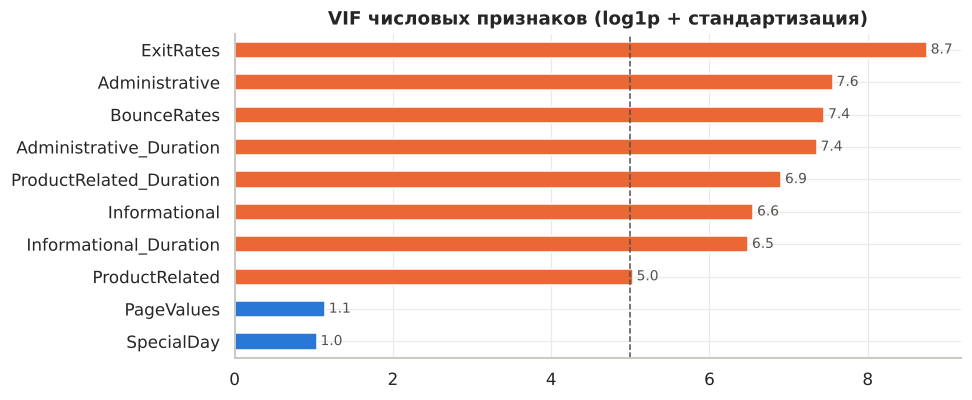

In [9]:
Zn = Z_train[NUMERIC].assign(const=1.0)
vif = pd.Series([variance_inflation_factor(Zn.values, i) for i in range(len(NUMERIC))], index=NUMERIC, name="VIF")
fig, ax = plt.subplots(figsize=(9, 3.8))
vif.sort_values().plot.barh(ax=ax, color=[viz.ORANGE if v > 5 else viz.BLUE for v in vif.sort_values()])
ax.axvline(5, ls="--", color="#52514e", lw=1)
ax.set_title("VIF числовых признаков (log1p + стандартизация)")
for i, v in enumerate(vif.sort_values()):
    ax.text(v + 0.05, i, f"{v:.1f}", va="center", fontsize=9, color="#52514e")
plt.tight_layout(); plt.show()

**Мультиколлинеарность есть.** VIF > 5 у восьми признаков из десяти: максимум у `ExitRates` (8,7), затем `Administrative` (7,6), `BounceRates` и `Administrative_Duration` (7,4). Это ожидаемо после lab3: три пары «счётчик — длительность» и пара `BounceRates`–`ExitRates` сильно согласованы. У `PageValues` и `SpecialDay` VIF ≈ 1.

**Что делаю:** признаки не удаляю. Для деревьев мультиколлинеарность на качество не влияет (только «размазывает» важность между похожими признаками). Для логистической регрессии использую L2-регуляризацию, которая стабилизирует коэффициенты, и при интерпретации смотрю на пары согласованных признаков вместе, а не на знак отдельного коэффициента.

## 6. Разбиение на train / test
Тестовая выборка (20 %) откладывается до финальной оценки моделей и в подборе параметров не участвует. Разбиение стратифицировано по `Revenue`. Все преобразования (`log1p` не обучается, а `StandardScaler` и `OneHotEncoder` — обучаются) живут внутри `Pipeline` и обучаются только на train, поэтому статистики тестовой выборки в модель не просачиваются.

In [10]:
split_tbl = pd.DataFrame({
    "сессий": [len(y_train), len(y_test)],
    "покупок": [int(y_train.sum()), int(y_test.sum())],
    "доля покупок": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
display(split_tbl.style.format({"доля покупок": "{:.2%}"}))

Z_test = pre_lin.transform(X_test)
print("Матрица для линейных моделей: train", Z_train.shape, "| test", Z_test.shape)
print("Пропусков после преобразования:", int(Z_train.isna().sum().sum() + Z_test.isna().sum().sum()))
print("Средние числовых признаков: train ≈ 0 (по построению), test:",
      Z_test[NUMERIC].mean().abs().max().round(3), "— максимум |среднего|, не ноль: скейлер обучен только на train")
Z_train.rename(columns=dict(zip(Z_train.columns, pretty_names(Z_train.columns)))).head()

,сессий,покупок,доля покупок
train,9864,1526,15.47%
test,2466,382,15.49%


Матрица для линейных моделей: train (9864, 58) | test (2466, 58)
Пропусков после преобразования: 0
Средние числовых признаков: train ≈ 0 (по построению), test: 0.031 — максимум |среднего|, не ноль: скейлер обучен только на train


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,PageValues,BounceRates,ExitRates,SpecialDay,...,TrafficType_8,TrafficType_10,TrafficType_11,TrafficType_13,TrafficType_20,TrafficType_other,VisitorType_New_Visitor,VisitorType_Returning_Visitor,VisitorType_other,Weekend
4263,1.621586,1.814356,-0.47956,-0.465251,0.600906,0.609918,1.539192,-0.353793,-0.612923,3.663440,...,0,0,0,0,0,0,0,1,0,0
5905,-0.925700,-0.977627,-0.47956,-0.465251,-1.133047,-0.434055,-0.493084,0.360698,1.159262,-0.311499,...,0,0,0,0,0,0,0,1,0,1
9434,-0.925700,-0.977627,-0.47956,-0.465251,-1.133047,-1.069069,-0.493084,-0.458865,0.136746,-0.311499,...,0,0,0,0,0,0,0,1,0,0
3505,0.347943,1.487872,-0.47956,-0.465251,0.008362,0.556334,1.870582,-0.202751,-0.118883,3.663440,...,0,0,0,0,0,0,0,1,0,0
2067,-0.925700,-0.977627,-0.47956,-0.465251,0.548475,0.373170,2.666006,-0.458865,-0.873776,-0.311499,...,0,0,0,0,0,0,0,1,0,0


## 7. Проверка: влияют ли выбранные преобразования на качество
Сравниваю три варианта подготовки для двух моделей, чувствительных к представлению признаков, — логистической регрессии и kNN (k = 25). Оценка — ROC-AUC на 5-кратной стратифицированной кросс-валидации **только по train**:

* **A.** «как есть»: числовые признаки без преобразований, коды и `Month`/`VisitorType` — порядковыми номерами (label encoding), без масштабирования;
* **B.** one-hot для номинальных + `StandardScaler`, без `log1p`;
* **C.** one-hot + `log1p` + `StandardScaler` — выбранный вариант (`make_preprocessor("linear")`).

модель,kNN (k = 25),Логистическая регрессия
подготовка,,
A: как есть + label encoding,0.8060,0.8925
B: one-hot + scaler,0.8573,0.8943
C: one-hot + log1p + scaler,0.9125,0.9157


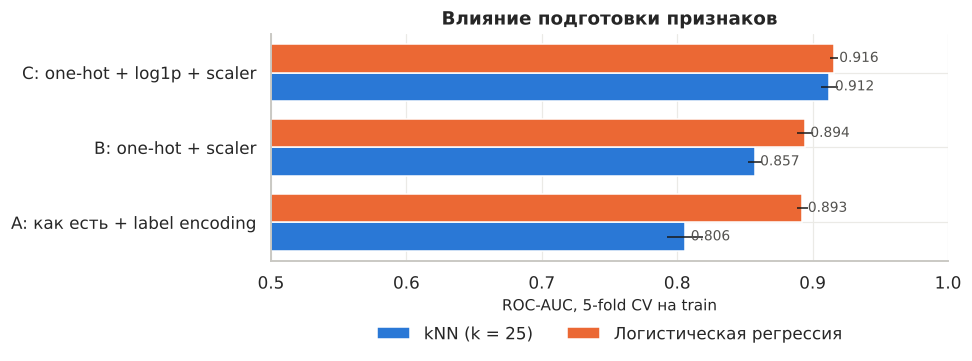

In [11]:
pre_A = ColumnTransformer([("num", "passthrough", NUMERIC),
                           ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), NOMINAL),
                           ("bin", "passthrough", BINARY)])
variants = {"A: как есть + label encoding": lambda: pre_A,
            "B: one-hot + scaler": lambda: make_preprocessor("linear", log=False),
            "C: one-hot + log1p + scaler": lambda: make_preprocessor("linear", log=True)}
models = {"Логистическая регрессия": lambda: LogisticRegression(max_iter=2000),
          "kNN (k = 25)": lambda: KNeighborsClassifier(n_neighbors=25)}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
res = []
for vn, vf in variants.items():
    for mn, mf in models.items():
        sc = cross_val_score(make_pipeline(vf(), mf()), X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
        res.append({"подготовка": vn, "модель": mn, "ROC-AUC (среднее)": sc.mean(), "ст. откл.": sc.std()})
res = pd.DataFrame(res)
piv = res.pivot(index="подготовка", columns="модель", values="ROC-AUC (среднее)")
display(piv.round(4))

fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.38
x = np.arange(len(piv))
for i, m in enumerate(piv.columns):
    vals = piv[m].values
    errs = res[res["модель"] == m].set_index("подготовка").loc[piv.index, "ст. откл."].values
    ax.barh(x + (i - .5) * w, vals, height=w, xerr=errs, color=viz.CATEGORICAL[i], label=m, error_kw={"elinewidth": 1})
    for xi, v in zip(x + (i - .5) * w, vals):
        ax.text(v + 0.004, xi, f"{v:.3f}", va="center", fontsize=9, color="#52514e")
ax.set_yticks(x, piv.index); ax.set_xlim(0.5, 1.0); ax.set_xlabel("ROC-AUC, 5-fold CV на train")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2); ax.set_title("Влияние подготовки признаков")
plt.tight_layout(); plt.show()

**Вывод по проверке.** Подготовка заметно влияет на модели, чувствительные к представлению признаков:
* **kNN** — сильнее всего: 0,806 («как есть») → 0,857 (one-hot + масштабирование) → 0,912 (+ `log1p`). Без масштабирования расстояние определяют признаки в секундах; без `log1p` — несколько сессий с огромными длительностями.
* **Логистическая регрессия**: 0,893 → 0,894 → 0,916. One-hot вместо номеров кодов почти ничего не дал по ROC-AUC (номинальные признаки в этих данных дают немного, lab3), а `log1p` добавил больше 0,02: линейная модель на логарифмической шкале лучше описывает скошенные признаки.

Значит, выбранный вариант C обоснован не только теоретически, но и на данных. Для деревьев (lab5) использую one-hot без масштабирования.

## 8. Итог: конвейер подготовки

In [12]:
pre_lin

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('log1p',
                                                  ColumnTransformer(remainder='passthrough',
                                                                    transformers=[('skewed',
                                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                                       func=<ufunc 'log1p'>),
                                                                                   ['Administrative',
                                                                                    'Administrative_Duration',
                                                                                    'Informational',
                                                                                    'Informational_Duration',
                              

**Итог lab4.**
* Матрица признаков для kNN / логистической регрессии / SVM: 58 столбцов = 10 числовых (`log1p` для 7 скошенных, затем стандартизация) + 47 one-hot + `Weekend`.
* Для деревьев и бустинга: те же 58 столбцов, но числовые признаки в исходных единицах (`encode_for_trees`), что удобно для интерпретации и дашборда.
* Train / test = 9 864 / 2 466 сессий, доля покупок 15,47 % / 15,49 %. Тест не используется до финальной оценки в lab5.
* Label encoding не применяется ни к одному номинальному признаку; единственный признак с очевидным порядком — `SpecialDay` — уже числовой.
* Дубликаты и выбросы сохранены (обоснование в п. 4), мультиколлинеарность учитывается регуляризацией.